# Radial distribution functions

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj

In [22]:
trj = mdtraj.load('../fixq/traj.dcd', top='../emim_tfsi/config.pdb')
print(trj)

dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)
<mdtraj.Trajectory with 2000 frames, 10200 atoms, 600 residues, and unitcells>


In [23]:
atoms, bonds = trj.topology.to_dataframe()
atoms.head()

,serial,name,element,resSeq,resName,chainID,segmentID,formal_charge
0,1,N1,N,1,c2c,0,,<NA>
1,2,C1,C,1,c2c,0,,<NA>
2,3,N2,N,1,c2c,0,,<NA>
3,4,C2,C,1,c2c,0,,<NA>
4,5,C3,C,1,c2c,0,,<NA>


In [24]:
res = pd.unique(atoms['resName'])
res

array(['c2c', 'tf2'], dtype=object)

Identify species

In [25]:
mols = pd.DataFrame(index=res, columns=['natoms', 'nmols'])
for spec in res:
    #mols[spec] = trj.topology.select(f"resname {spec}")
    moli = atoms.query(f"resName == '{spec}'").index
    i = moli[0]
    j = moli[-1]
    nmols = atoms.iloc[j].resSeq - atoms.iloc[i].resSeq + 1
    natoms = int((j - i + 1) / nmols)
    mols.loc[spec] = [natoms, nmols]
print(mols)

    natoms nmols
c2c     19   300
tf2     15   300


In [26]:
def showatoms(atoms, mols, res):
    offset = atoms.query(f"resName == '{res}'").index[0]
    print(atoms[offset:offset+mols.loc[res].natoms])

In [27]:
showatoms(atoms, mols, 'c2c')

    serial name element  resSeq resName  chainID segmentID  formal_charge
0        1   N1       N       1     c2c        0                     <NA>
1        2   C1       C       1     c2c        0                     <NA>
2        3   N2       N       1     c2c        0                     <NA>
3        4   C2       C       1     c2c        0                     <NA>
4        5   C3       C       1     c2c        0                     <NA>
5        6   C4       C       1     c2c        0                     <NA>
6        7   H1       H       1     c2c        0                     <NA>
7        8   C5       C       1     c2c        0                     <NA>
8        9   H2       H       1     c2c        0                     <NA>
9       10   H3       H       1     c2c        0                     <NA>
10      11   H4       H       1     c2c        0                     <NA>
11      12   H5       H       1     c2c        0                     <NA>
12      13   H6       H       1     c2

In [28]:
showatoms(atoms, mols, 'tf2')

      serial name element  resSeq resName  chainID segmentID  formal_charge
5700    5701   C1       C     301     tf2        0                     <NA>
5701    5702   F1       F     301     tf2        0                     <NA>
5702    5703   F2       F     301     tf2        0                     <NA>
5703    5704   F3       F     301     tf2        0                     <NA>
5704    5705   S1       S     301     tf2        0                     <NA>
5705    5706    N       N     301     tf2        0                     <NA>
5706    5707   O1       O     301     tf2        0                     <NA>
5707    5708   O2       O     301     tf2        0                     <NA>
5708    5709   S2       S     301     tf2        0                     <NA>
5709    5710   O3       O     301     tf2        0                     <NA>
5710    5711   O4       O     301     tf2        0                     <NA>
5711    5712   C2       C     301     tf2        0                     <NA>
5712    5713

In [29]:
top = trj.topology
ati = top.select("resname c2c and name == C1")
atj = top.select("resname tf2 and element == O")
pairs = [ [i, j] for i in ati for j in atj ]

In [30]:
len(ati), len(atj), len(pairs)

(300, 1200, 360000)

In [31]:
rdf = mdtraj.compute_rdf(trj, pairs, bin_width=0.01, r_range=(0.0, 1.6))

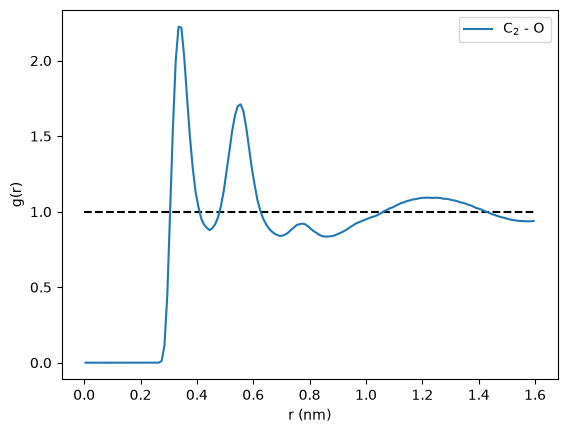

In [32]:
fig, ax = plt.subplots()
ax.plot((0, 1.6), (1, 1), 'k--')
ax.plot(rdf[0], rdf[1], label='C$_2$ - O')
ax.set_xlabel('r (nm)')
ax.set_ylabel('g(r)')
#ax.set_ylim(0, 5)
ax.legend()
plt.show()